# Gate5A: Expander-coupled Matryoshka Attribution

Local adapter over the pinned official edge-MAttr trainer. All 32,491 scores remain eligible; raw zero initialization, Adam, uniform-k, precision and MIB interventions are unchanged. Effective scores are `(1-beta)*s + beta*P@s`. For beta below 0.5 this is an invertible reparameterization, not a richer function class.

Training is disabled by default. This notebook reads the actual registered campaign; it does not substitute data or invent results.

In [1]:
from pathlib import Path
import json, os, subprocess
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/mattr_expander").is_dir())
CAMPAIGN_REL = "results/mattr_expander/20261022_gate5a"
CAMPAIGN = ROOT / CAMPAIGN_REL
RUN_TESTS = False
RUN_PREPARE = False
RUN_REGISTERED_CAMPAIGN = False
REGENERATE_REPORT = False
print("Campaign:", CAMPAIGN)

Campaign: H:\GenAI Research\sketch_prune\results\mattr_expander\20261022_gate5a


## Explicit execution controls

The existing WSL runtime is used on Windows. The registered runner performs Phase A before Phase B and stops if correctness or advancement gates fail. Repeating the command reuses verified completed jobs; it does not create another sweep. Do not edit a frozen campaign protocol.

In [2]:
def run_registered(*args):
    script = ROOT / "src/mattr_expander/run_wsl.sh"
    if os.name == "nt":
        wsl_script = "/mnt/" + script.drive[0].lower() + str(script)[2:].replace("\\", "/")
        command = ["wsl", "-d", "Ubuntu", "--", "bash", wsl_script, *args]
    else:
        command = ["bash", str(script), *args]
    subprocess.run(command, cwd=ROOT, check=True)
if RUN_TESTS:
    run_registered("tests")
if RUN_PREPARE:
    run_registered("--out", CAMPAIGN_REL, "--prepare-only")
if RUN_REGISTERED_CAMPAIGN:
    run_registered("--out", CAMPAIGN_REL)
if REGENERATE_REPORT:
    run_registered("--out", CAMPAIGN_REL, "--report-only")

## Frozen graph and experiment configuration

G0: degree8 ring; G1: E/4 successful degree-preserving swaps; G2: random regular candidate. Graph seed1701 is fixed across training seeds42/43/44. Both betas0.10/0.25 and both scale-only controls are prespecified. Spectral diagnostics use sparse matrices, never dense production adjacency.

In [3]:
protocol = json.loads((CAMPAIGN / "gate5a_protocol.json").read_text())
print("Protocol SHA-256:", (CAMPAIGN / "gate5a_protocol.sha256").read_text().strip())
display(pd.read_csv(CAMPAIGN / "graph_spectral_statistics.csv")[["family", "vertices", "edges", "degree_min", "components", "laplacian_gap", "nontrivial_adjacency_magnitude", "generation_seconds", "spectral_seconds"]])
print(json.dumps(protocol["criteria"], indent=2))

Protocol SHA-256: 177f98a8751f408d80ac965ad9e46f67715f3c6458be03a81f48c3beded8a4e2


,family,vertices,edges,degree_min,components,laplacian_gap,nontrivial_adjacency_magnitude,generation_seconds,spectral_seconds
0,G0,32491,129964,8,1,1.402377e-07,1.000000,0.002173,0.001472
1,G1,32491,129964,8,1,1.480433e-01,0.851957,0.426779,0.165288
2,G2,32491,129964,8,1,3.389853e-01,0.661015,0.649861,0.354581
3,G2perm,32491,129964,8,1,3.389853e-01,0.661015,0.649861,0.354581


{
  "primary_CPR_gain": 0.02,
  "positive_seeds": 2,
  "compact_drop": 0.02,
  "accuracy_auc_drop": 0.02,
  "compact_fractions": [
    0.005,
    0.01,
    0.02,
    0.05
  ],
  "CMD_guard": "max(0, mean paired CPR increase)+.05",
  "adaptation_time_ratio_max": 1.15,
  "allocated_memory_ratio_max": 1.1,
  "efficiency": {
    "CPR_loss_max": 0.01,
    "CMD_increase_max": 0.1,
    "accuracy_drop_max": 0.02,
    "accuracy_auc_drop_max": 0.02,
    "compute_saving_min": 0.2
  },
  "expander_specific": "G2 must beat G0, G1 AND scale-only by>=.5% mean paired relative CPR and>=2 positive seeds, with compact/AUC safeguards, at the same beta/budget; final claim additionally requires permutation control to pass baseline quality guards; one graph instance gives no causal spectral-gap claim"
}


## Actual outcomes

The development cohort is held out from discovery training but reused across gates. Single-seed screening cannot establish reproducibility, ranking stability across seeds or generalization. A failed earlier gate leaves modified5000-step performance untested.

In [4]:
for filename in ["phaseB_decision.json", "phaseC_decision.json", "final_decision.json", "final_validation.json"]:
    path = CAMPAIGN / filename
    if path.exists():
        print(filename)
        display(json.loads(path.read_text()))
    else:
        print(filename, "not run / not yet available")
display(pd.read_csv(CAMPAIGN / "paired_results.csv").query("step == 1000")[["family", "beta", "seed", "cpr", "cpr_delta", "relative_cpr_gain", "cmd_delta", "accuracy_auc_delta", "time_ratio"]])

phaseB_decision.json


{'exploratory': True,
 'selected': [{'family': 'G1', 'beta': 0.1}],
 'results': [{'family': 'G0',
   'beta': 0.1,
   'primary_plausibility': {'passed': False,
    'checks': {'CPR_gain': False,
     'CMD_guard': True,
     'time_guard': True,
     'memory_guard': True,
     'accuracy_auc_guard': True,
     'compact_0.005': True,
     'compact_0.01': True,
     'compact_0.02': True,
     'compact_0.05': True}},
   'efficiency': {'passed': False,
    'checks': {'CPR_noninferiority': False,
     'CMD_guard': True,
     'compute_saving': True,
     'accuracy_auc_guard': False,
     'compact_0.005': False,
     'compact_0.01': False,
     'compact_0.02': True,
     'compact_0.05': True}},
   'relative_cpr_gain': 0.0020372767113463475},
  {'family': 'G0',
   'beta': 0.25,
   'primary_plausibility': {'passed': False,
    'checks': {'CPR_gain': False,
     'CMD_guard': True,
     'time_guard': True,
     'memory_guard': True,
     'accuracy_auc_guard': True,
     'compact_0.005': True,
     'co

phaseC_decision.json


{'winner': None,
 'results': [{'family': 'G1',
   'beta': 0.1,
   'primary_provisional': {'passed': False,
    'checks': {'CPR_gain': False,
     'CMD_guard': True,
     'time_guard': True,
     'memory_guard': True,
     'positive_seeds': False,
     'accuracy_auc_guard': True,
     'compact_0.005': False,
     'compact_0.01': False,
     'compact_0.02': True,
     'compact_0.05': True}},
   'efficiency': {'passed': False,
    'checks': {'CPR_noninferiority': False,
     'CMD_guard': True,
     'compute_saving': True,
     'accuracy_auc_guard': False,
     'compact_0.005': False,
     'compact_0.01': False,
     'compact_0.02': True,
     'compact_0.05': True}},
   'G2_topology_controls': {'G0': {'passed': True,
     'checks': {'relative_CPR_gain': True,
      'positive_seeds': True,
      'accuracy_auc': True,
      'compact_0.005': True,
      'compact_0.01': True,
      'compact_0.02': True,
      'compact_0.05': True}},
    'G1': {'passed': False,
     'checks': {'relative_CPR_gai

final_decision.json not run / not yet available
final_validation.json


{'passed': True,
 'historical_files_unchanged': 4033,
 'historical_Gate3_criteria_sha256': 'f200fc163bfb0e70b4790bde28ed3a6748bf9051c7d574ed7e23bda69cf0dbde',
 'protocol_sha256': '177f98a8751f408d80ac965ad9e46f67715f3c6458be03a81f48c3beded8a4e2',
 'cpu_tests': 6,
 'all_graphs_degree8_connected': True,
 'canonical_mapping_bijective': True,
 'beta_zero_bitwise_matches_Gate2': True,
 'raw_checkpoints_effective_rankings_verified': True,
 'paired_example_and_k_streams_equal': True,
 'inference_no_grad_verified': True,
 'totals': {'forward_batches': 28111,
  'example_forwards': 141367,
  'backward_calls': 19090,
  'optimizer_updates': 19090},
 'actual_child_launch_seconds': 7332.628940554,
 'phaseB_selected': [{'family': 'G1', 'beta': 0.1}],
 'phaseD_executed': False,
 'leaderboard_submission': False,
 'additional_model_forwards_for_audit': 0,
 'audit_seconds': 23.77667589199973}

,family,beta,seed,cpr,cpr_delta,relative_cpr_gain,cmd_delta,accuracy_auc_delta,time_ratio
0,G0,0.10,42,9.967941,2.026617e-02,2.037277e-03,1.879125e-02,0.014111,1.027810
2,G0,0.10,43,10.089899,-1.725210e-01,-1.681095e-02,-1.725799e-01,0.000000,1.005427
4,G0,0.10,44,9.757595,-3.488785e-01,-3.452030e-02,-3.434677e-01,-0.052191,0.987815
6,G0,0.25,42,9.900087,-4.758820e-02,-4.783851e-03,-4.760124e-02,0.001568,1.040683
8,G1,0.10,42,10.024610,7.693494e-02,7.733962e-03,7.500808e-02,0.014769,1.005149
10,G1,0.10,43,10.206775,-5.564545e-02,-5.422254e-03,-5.457289e-02,-0.021843,1.020630
12,G1,0.10,44,9.924271,-1.822019e-01,-1.802824e-02,-1.774457e-01,-0.049028,0.993118
14,G1,0.25,42,9.762912,-1.847631e-01,-1.857350e-02,-1.874619e-01,0.018814,1.016521
16,G2,0.10,42,9.985786,3.811105e-02,3.831152e-03,3.870226e-02,-0.003262,1.056407
18,G2,0.10,43,10.083728,-1.786926e-01,-1.741232e-02,-1.790012e-01,-0.002730,1.017911


## Compute, gradients and structure

Actual root forwards, examples, backward calls and updates are counted separately. Graph construction and mixing are charged. Spectra are reported separately. Raw checkpoints and effective exports remain local; official retained sets determine circuit overlap.

In [5]:
display(pd.read_csv(CAMPAIGN / "compute_accounting.csv"))
display(pd.read_csv(CAMPAIGN / "gradient_diagnostics.csv").head(12))
display(pd.read_csv(CAMPAIGN / "ranking_stability.csv").head(12))
display(pd.read_csv(CAMPAIGN / "structural_score_statistics.csv").head(12))

,job,adaptation_seconds,training_seconds,evaluation_seconds,stage_seconds,peak_allocated_mib,cpu_rss_mib,forward_batches,example_forwards,backward_calls,optimizer_updates
0,G0_b0.1_s42,313.187382,305.580879,55.655798,366.856743,3913.587402,2873.203125,1464,7272,1000,1000
1,G0_b0.1_s43,312.384193,304.240525,55.598683,366.004520,3908.482910,2937.605469,1464,7272,1000,1000
2,G0_b0.1_s44,310.758612,301.973469,54.965795,363.785119,3902.349609,2958.683594,1464,7272,1000,1000
3,G0_b0.25_s42,317.110191,308.416119,55.615916,370.646674,3913.587402,2970.175781,1464,7272,1000,1000
4,G1_b0.1_s42,305.838932,297.284032,55.678779,359.460107,3913.587402,2957.582031,1464,7272,1000,1000
5,G1_b0.1_s43,316.664778,308.031742,55.473767,369.858760,3908.482910,2983.085938,1464,7272,1000,1000
6,G1_b0.1_s44,311.983794,304.122119,56.541259,366.545234,3902.349609,2897.210938,1464,7272,1000,1000
7,G1_b0.25_s42,309.304293,300.763167,55.912072,363.178595,3913.587402,2883.863281,1464,7272,1000,1000
8,G2_b0.1_s42,321.252413,312.707951,56.998671,376.058001,3913.587402,2936.300781,1464,7272,1000,1000
9,G2_b0.1_s43,315.613947,307.312465,55.735278,369.424463,3908.482910,2895.320312,1464,7272,1000,1000


,step,raw_gradient_norm,effective_gradient_norm,raw_score_variance,effective_score_variance,raw_gradient_top_score_fraction,effective_gradient_top_score_fraction,rank_spearman_since_previous,top1pct_jaccard_since_previous,family,beta,seed
0,1,2.523186,2.799632,0.000000,0.000000,0.030728,0.030100,NaN,NaN,G0,0.1,42
1,50,4.107734,4.546478,0.255909,0.220542,0.102362,0.101553,0.366154,0.161290,G0,0.1,42
2,100,0.084074,0.093282,0.495784,0.418870,0.448486,0.472092,0.583537,0.436807,G0,0.1,42
3,150,1.435390,1.584765,0.667100,0.561334,0.058501,0.057576,0.764122,0.644670,G0,0.1,42
4,200,1.083826,1.204876,0.799587,0.668777,0.001724,0.000715,0.778763,0.780220,G0,0.1,42
5,250,1.264262,1.405939,0.906789,0.758644,0.001627,0.000164,0.853558,0.760870,G0,0.1,42
6,300,1.324574,1.472389,0.986768,0.823824,0.002743,0.001858,0.840563,0.800000,G0,0.1,42
7,350,2.064027,2.293719,1.081958,0.902575,0.001311,0.000252,0.882622,0.911504,G0,0.1,42
8,400,1.265003,1.403492,1.211408,1.008305,0.003118,0.001761,0.864226,0.723404,G0,0.1,42
9,450,2.050661,2.276399,1.287628,1.071533,0.008616,0.007636,0.905486,0.790055,G0,0.1,42


,family,beta,step,fraction,seed_a,seed_b,jaccard
0,G0,0.1,500,0.005,42,43,0.212903
1,G0,0.1,500,0.005,42,44,0.149254
2,G0,0.1,500,0.005,43,44,0.128571
3,G0,0.1,500,0.010,42,43,0.410448
4,G0,0.1,500,0.010,42,44,0.438642
5,G0,0.1,500,0.010,43,44,0.439791
6,G0,0.1,500,0.020,42,43,0.514528
7,G0,0.1,500,0.020,42,44,0.578880
8,G0,0.1,500,0.020,43,44,0.505402
9,G0,0.1,500,0.050,42,43,0.470912


,family,beta,seed,step,category,mean,std,min,max,count,grouping
0,Gate2,0.0,42,500,MLP,-0.382103,1.835380,-6.270101,4.537645,2454,source_type
1,Gate2,0.0,42,500,attention,-0.708242,0.998274,-6.074566,4.634039,29592,source_type
2,Gate2,0.0,42,500,input,-0.562351,1.196031,-5.462790,4.424512,445,source_type
3,Gate2,0.0,42,500,MLP,-0.558624,2.083186,-5.856662,4.511463,1014,destination_type
4,Gate2,0.0,42,500,attention,-0.689251,1.029577,-6.270101,4.537645,31320,destination_type
5,Gate2,0.0,42,500,logits,0.048198,2.453200,-5.456125,4.634039,157,destination_type
6,Gate2,0.0,42,500,a0.h0,-0.694287,0.437906,-3.032525,1.259397,409,source_component
7,Gate2,0.0,42,500,a0.h1,-0.682831,1.525945,-5.804853,4.114366,409,source_component
8,Gate2,0.0,42,500,a0.h10,-0.745242,1.161971,-4.744473,4.049696,409,source_component
9,Gate2,0.0,42,500,a0.h11,-0.707968,0.454993,-2.346741,3.017324,409,source_component


## Block, head and edge-type diagnostics

These summaries use saved effective rankings and official connectivity-pruned retained sets. They are descriptive only and never enter candidate selection. The raw ranking vectors remain outside Git; only aggregated statistics are saved.

In [6]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.mattr_optimization.gate3 import baseline

sources = []
for job in sorted((CAMPAIGN / "jobs").glob("*")):
    if not (job / "completed_1000.json").exists():
        continue
    cfg = json.loads((job / "experiment_config.json").read_text())
    for path in sorted(job.glob("ranking_*.csv")):
        step = int(path.stem.split("_")[1])
        sources.append((path, cfg["family"], cfg["beta"], cfg["seed"], step, job / f"membership_{step}.csv"))
for seed in [42, 43, 44]:
    path = baseline(seed) / "ranking.csv"
    if path.exists():
        sources.append((path, "Gate2", 0.0, seed, 5000, None))

score_summaries, retained_summaries = [], []
for path, family, beta, seed, step, membership_path in sources:
    ranks = pd.read_csv(path)
    assert ranks.edge.nunique() == 32491
    nodes = ranks.edge.str.split("->", n=1, expand=True)
    ranks["source_component"] = nodes[0]
    ranks["destination_component"] = nodes[1].str.replace(r"<.*>", "", regex=True)
    for side in ["source", "destination"]:
        node = ranks[f"{side}_component"]
        ranks[f"{side}_layer"] = node.str.extract(r"^[am](\d+)", expand=False).fillna("boundary")
        ranks[f"{side}_type"] = node.map(lambda s: "attention" if s.startswith("a") else "MLP" if s.startswith("m") else s)
    ranks["edge_type"] = ranks.source_type + "->" + ranks.destination_type
    ranks["destination_qkv"] = nodes[1].str.extract(r"<([qkv])>", expand=False).fillna("not_attention")
    axes = ["source_component", "destination_component", "source_layer", "destination_layer", "edge_type", "destination_qkv"]
    labels = {"family": family, "beta": beta, "seed": seed, "step": step}
    for axis in axes:
        summary = ranks.groupby(axis).score.agg(["mean", "std", "min", "max", "count"]).reset_index().rename(columns={axis: "category"})
        summary["grouping"] = axis
        score_summaries.append(summary.assign(**labels))
    if membership_path is not None and membership_path.exists():
        retained = pd.read_csv(membership_path)
        joined = retained.merge(ranks[["edge", *axes]], on="edge", validate="many_to_one")
        for axis in axes:
            eligible = ranks.groupby(axis).size()
            index = pd.MultiIndex.from_product([[.005, .01, .02, .05], eligible.index], names=["fraction", axis])
            counts = joined.groupby(["fraction", axis]).size().reindex(index, fill_value=0).rename("retained_edges").reset_index()
            counts["eligible_edges"] = counts[axis].map(eligible)
            counts["retention_rate"] = counts.retained_edges / counts.eligible_edges
            global_rate = retained.groupby("fraction").size() / 32491
            counts["retention_excess_vs_global"] = counts.retention_rate - counts.fraction.map(global_rate)
            counts = counts.rename(columns={axis: "category"})
            counts["grouping"] = axis
            retained_summaries.append(counts.assign(**labels))
structural = pd.concat(score_summaries, ignore_index=True)
structural.to_csv(CAMPAIGN / "block_head_edge_type_statistics.csv", index=False)
retention = pd.concat(retained_summaries, ignore_index=True)
retention.to_csv(CAMPAIGN / "structural_retention_statistics.csv", index=False)
display(structural.query("grouping == 'source_layer'").head(12))
display(retention.query("grouping == 'edge_type'").head(12))

,category,mean,std,min,max,count,grouping,family,beta,seed,step
314,0,-0.693489,1.277892,-7.388848,5.458574,5316,source_layer,G0,0.1,42,1000
315,1,-0.715500,0.993306,-5.950412,5.267103,4835,source_layer,G0,0.1,42,1000
316,10,-0.965192,2.221921,-6.698062,4.915903,506,source_layer,G0,0.1,42,1000
317,11,0.309726,4.932979,-6.443137,5.633696,25,source_layer,G0,0.1,42,1000
318,2,-0.763030,0.988655,-6.382042,4.873868,4354,source_layer,G0,0.1,42,1000
319,3,-0.745351,1.249813,-6.653924,5.280616,3873,source_layer,G0,0.1,42,1000
320,4,-0.715008,1.127489,-5.983528,5.986567,3392,source_layer,G0,0.1,42,1000
321,5,-0.778954,1.513104,-6.480486,5.347667,2911,source_layer,G0,0.1,42,1000
322,6,-0.700461,1.562634,-7.145758,5.771264,2430,source_layer,G0,0.1,42,1000
323,7,-0.743092,1.688194,-6.705527,4.908800,1949,source_layer,G0,0.1,42,1000


,fraction,category,retained_edges,eligible_edges,retention_rate,retention_excess_vs_global,grouping,family,beta,seed,step
1360,0.005,MLP->MLP,3,66,0.045455,0.042500,edge_type,G0,0.1,42,1000
1361,0.005,MLP->attention,33,2376,0.013889,0.010934,edge_type,G0,0.1,42,1000
1362,0.005,MLP->logits,2,12,0.166667,0.163712,edge_type,G0,0.1,42,1000
1363,0.005,attention->MLP,22,936,0.023504,0.020550,edge_type,G0,0.1,42,1000
1364,0.005,attention->attention,28,28512,0.000982,-0.001973,edge_type,G0,0.1,42,1000
1365,0.005,attention->logits,4,144,0.027778,0.024823,edge_type,G0,0.1,42,1000
1366,0.005,input->MLP,1,12,0.083333,0.080379,edge_type,G0,0.1,42,1000
1367,0.005,input->attention,3,432,0.006944,0.003990,edge_type,G0,0.1,42,1000
1368,0.005,input->logits,0,1,0.000000,-0.002955,edge_type,G0,0.1,42,1000
1369,0.010,MLP->MLP,5,66,0.075758,0.066894,edge_type,G0,0.1,42,1000


## Saved figures

All plots use measured results only. CPR versus gap is exploratory, with one graph instance per family. Scale-only and degree-matched controls are necessary before attributing an effect to expansion.

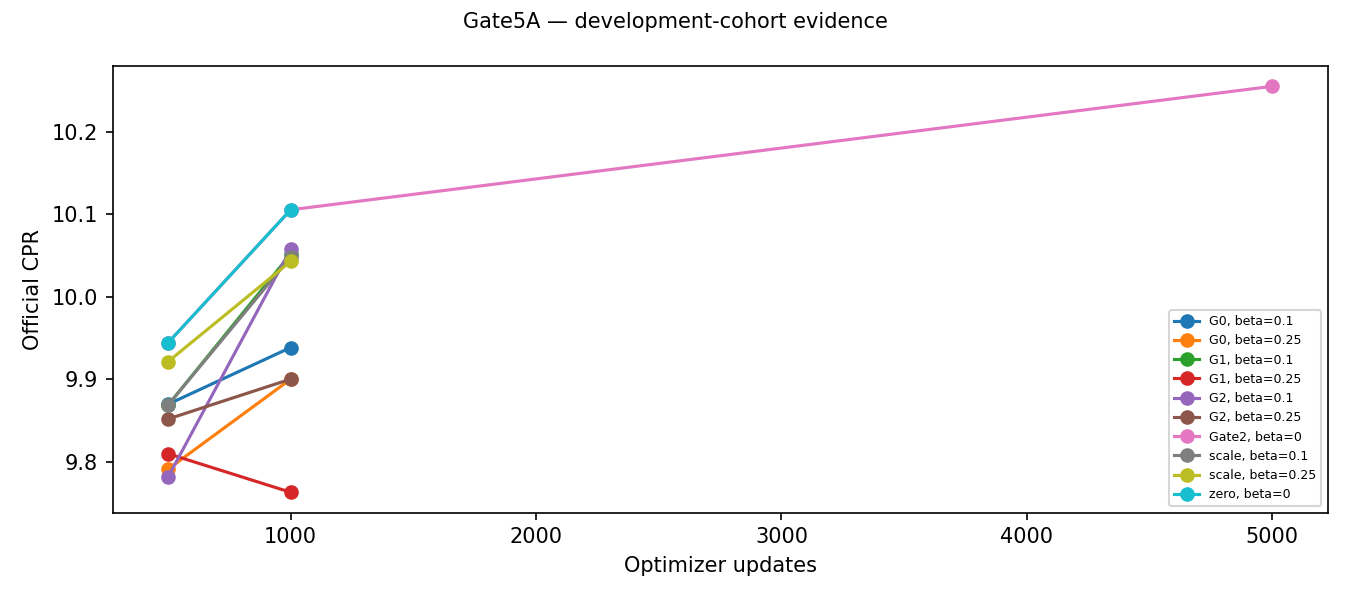

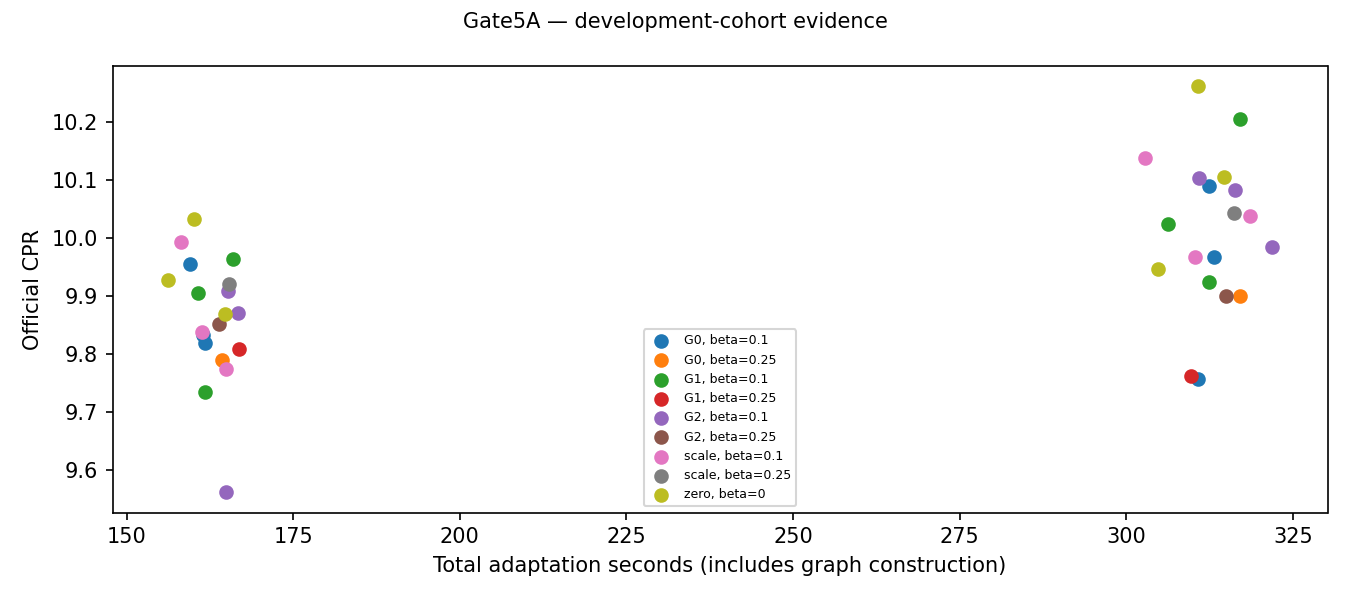

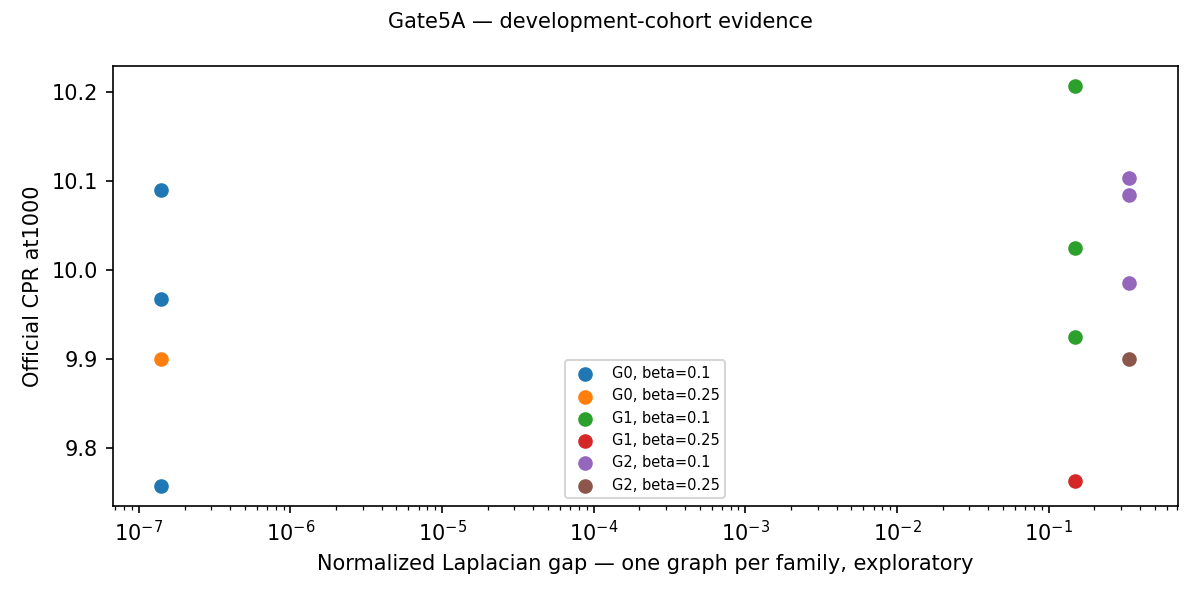

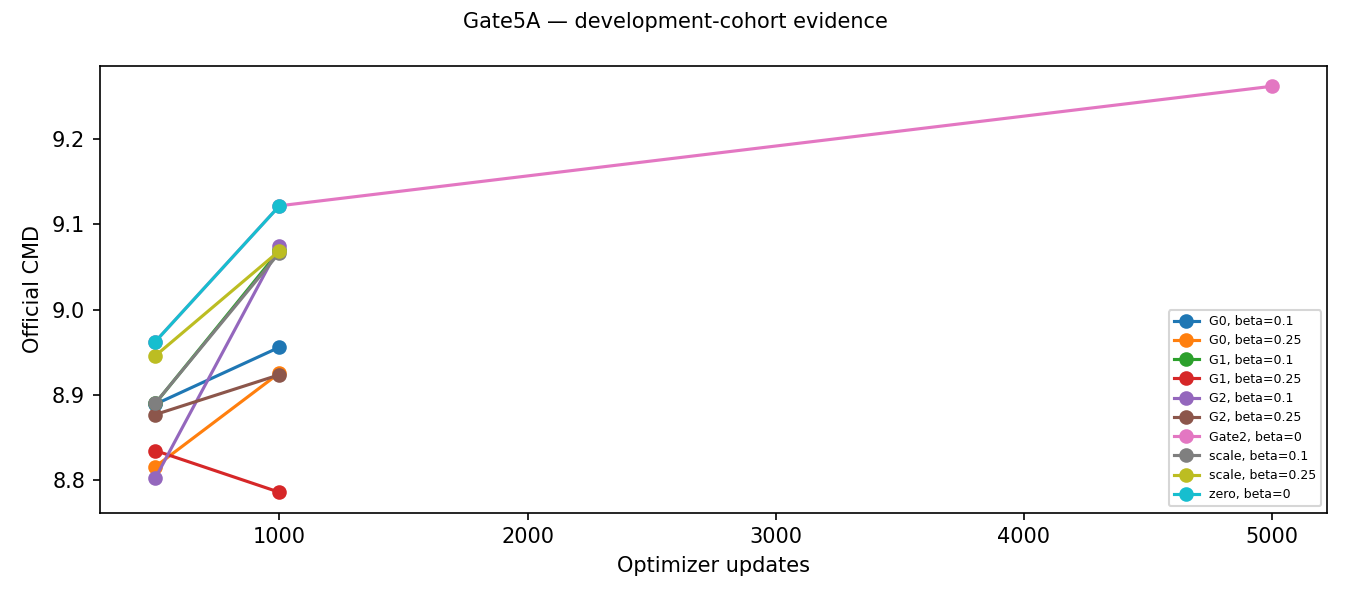

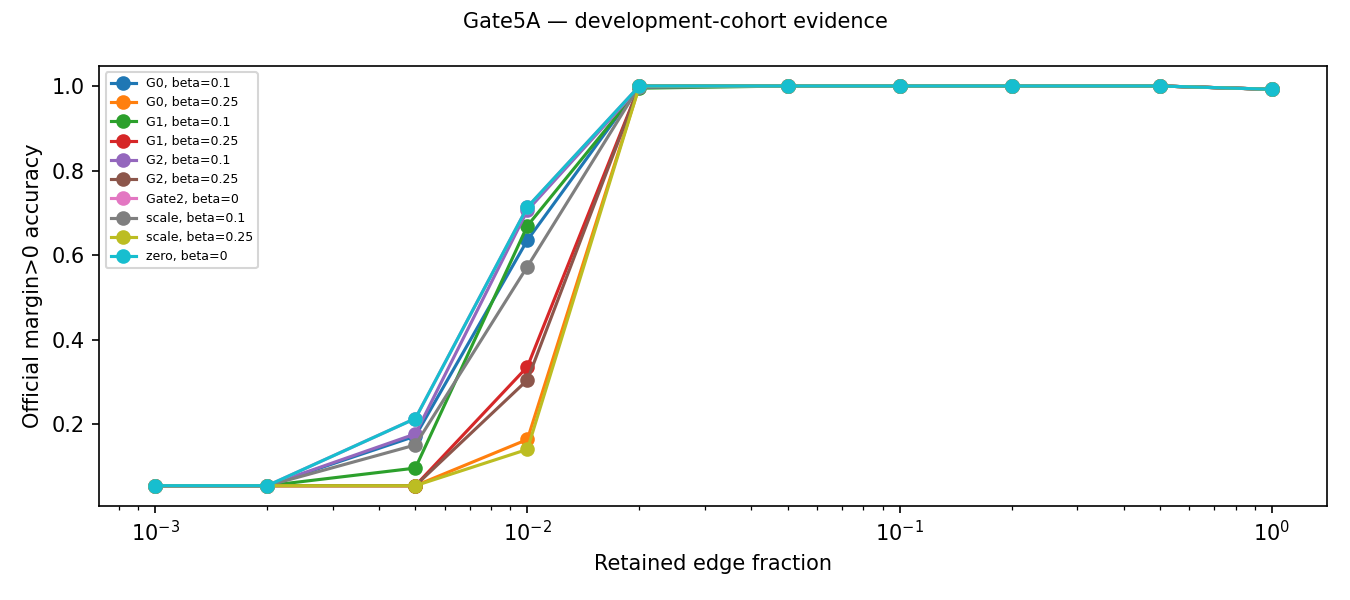

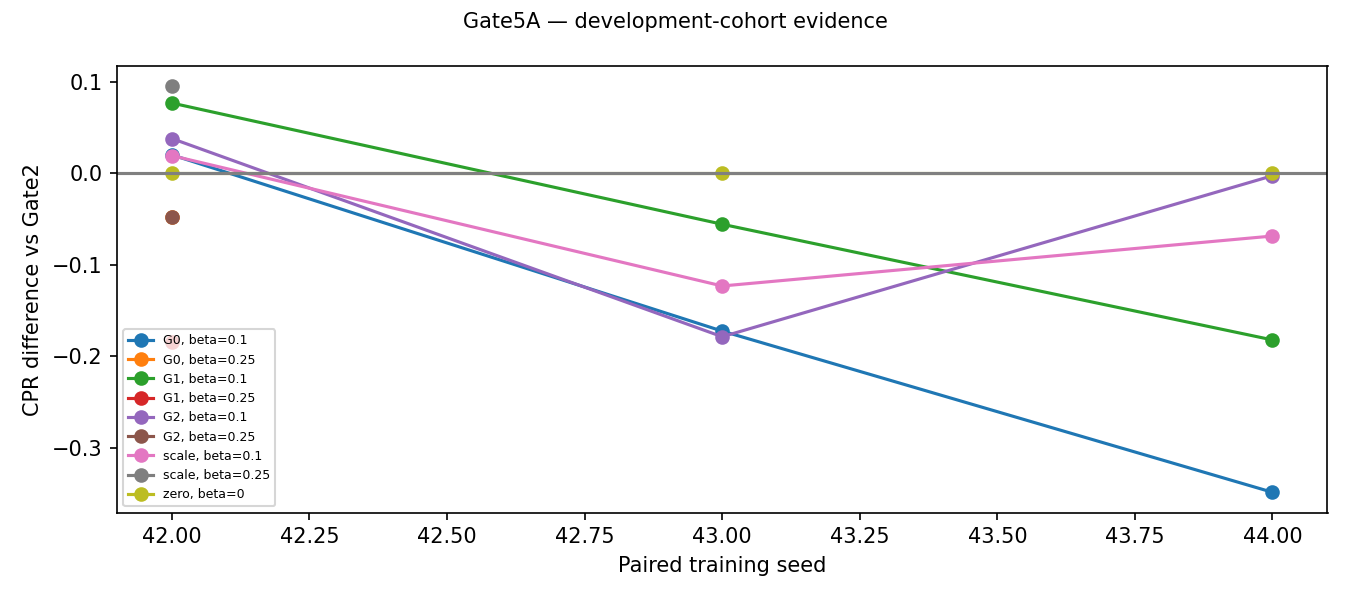

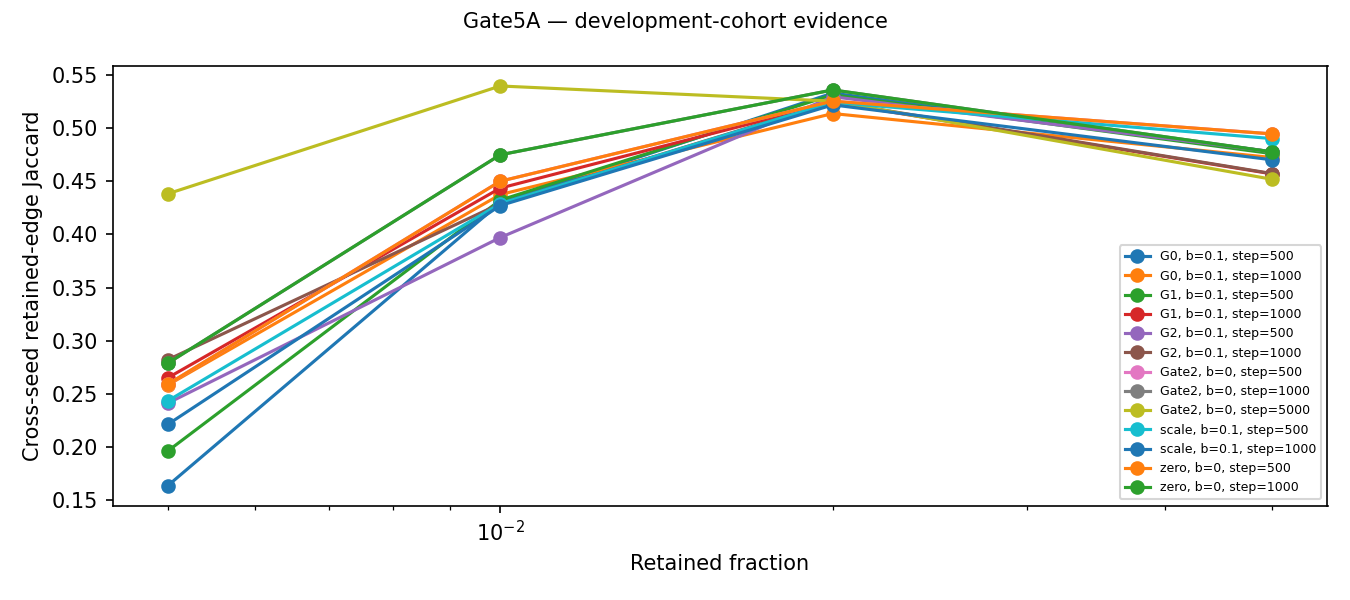

In [7]:
for name in ["cpr_vs_updates", "cpr_vs_compute", "cpr_vs_gap", "cmd_vs_updates", "compact_accuracy", "paired_cpr", "ranking_stability"]:
    path = CAMPAIGN / "figures" / f"{name}.png"
    if path.exists():
        display(Image(filename=str(path)))

## Research report

Read the report for phase stopping decisions, fidelity versus CPR tradeoffs and limitations. No deferred refinement, full-data multi-model experiment or leaderboard submission is authorized by this notebook.

In [8]:
import hashlib
from src.mattr_optimization.gate2_final_analysis import table
full_path = ROOT / "results/mattr_optimization/20261021T134352Z_gate1/official_metrics.json"
dev_path = ROOT / "results/mattr_optimization/20261021_gate2_final/frozen/gate1_on_gate2_validation/official_result.json"
full = json.loads(full_path.read_text())
dev = json.loads(dev_path.read_text())["result"]
references = pd.DataFrame([
    {"training_examples": 10000, "validation_examples": full["validation_examples"], "seed": 42, "updates": 5000, "CPR": full["cpr"], "CMD": full["cmd"], "accuracy_log_AUC": full["accuracy_auc"], "scope": "Gate1 full official validation"},
    {"training_examples": 10000, "validation_examples": 128, "seed": 42, "updates": 5000, "CPR": dev[1], "CMD": dev[2], "accuracy_log_AUC": dev[6], "scope": "Frozen Gate1 ranking on Gate2 development cohort"},
])
references.to_csv(CAMPAIGN / "historical_full_data_reference.csv", index=False)
provenance = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [full_path, dev_path]}
(CAMPAIGN / "historical_reference_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
appendix = "\n\n## Historical full-data reference (additional context)\n\n" + table(references)
appendix += "\n\nThese are reused Gate1 results, with zero new model forwards or training. The full10000-validation result uses a different evaluation cohort. Neither row is the paired N128-training control; frozen Gate2 checkpoints remain the primary comparator.\n"
for path in [ROOT / "GATE5A_EXPANDER_MATTR_REPORT.md", CAMPAIGN / "GATE5A_EXPANDER_MATTR_REPORT.md"]:
    body = path.read_text().split("\n\n## Historical full-data reference")[0]
    path.write_text(body.rstrip() + appendix, encoding="utf-8")
display(references)

,training_examples,validation_examples,seed,updates,CPR,CMD,accuracy_log_AUC,scope
0,10000,10000,42,5000,10.588012,9.600809,0.737206,Gate1 full official validation
1,10000,128,42,5000,10.725481,9.738246,0.738303,Frozen Gate1 ranking on Gate2 development cohort


In [9]:
import re
report_text = (CAMPAIGN / "GATE5A_EXPANDER_MATTR_REPORT.md").read_text()
# Figures are displayed above; omit duplicate relative image links in this view.
report_text = re.sub(r"^!\[.*?\]\(.*?\)\s*$", "", report_text, flags=re.MULTILINE)
display(Markdown(report_text))

# Gate5A: Expander-coupled Matryoshka Attribution

Negative paired PhaseC result. No registered winner; PhaseD skipped.

Protocol SHA-256 `177f98a8751f408d80ac965ad9e46f67715f3c6458be03a81f48c3beded8a4e2`; implementation parent `f24406e52ee74abdf2370f832149b07ca3d552e4`. Historical Gate3 criteria remain `f200fc163bfb0e70b4790bde28ed3a6748bf9051c7d574ed7e23bda69cf0dbde`.

## Hypothesis and implementation

An auxiliary degree8 graph couples all32,491 learnable transformer-edge scores: s_effective=(1-beta)s+beta Ps. It changes score optimization, never transformer-edge eligibility. Raw scores initialize at zero; official Adam/lr.05, uniform-k, temperature.5, implicit sigmoid-top-k, live edge patching, model-weight gradient behavior and float32 remain unchanged. Only trainer-local build_mask receives effective scores. Official evaluation/export uses effective scores; raw scores and original Adam/RNG states remain in local checkpoints for exact resume. For undirected regular graphs and beta<.5 the linear map is invertible: this is reparameterization/conditioning, not an enlarged hypothesis class.

A custom symmetric linear backward uses the same fixed-degree gather/reduction as forward, P^T=P, avoiding CUDA scatter-add ordering. CPU/GPU values, gradients, finite differences, soft mass, beta0 exact trainer behavior and checkpoint continuation are tested. Graph8-neighbor indices are immutable during training. No N-square dense matrix is constructed.

## Graph construction and measured spectra

G0 is the +/-1..4 ring; G1 applies E//4=32,491 successful degree-preserving swaps; G2 is seeded NetworkX random regular. All use graph seed1701 and the identical canonical real-edge mapping across training seeds. G2 is labeled a candidate until its spectrum is measured. G0 uses analytic circulant eigenvalues; G1/G2 use sparse ARPACK and residual checks. Permutation2701 is fixed in advance and is used only for a selected G2 winner.

| family | vertices | edges | degree_min | degree_max | components | laplacian_gap | nontrivial_adjacency_magnitude | generation_seconds | spectral_seconds | neighbor_int32_bytes |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| G0 | 32491 | 129964 | 8 | 8 | 1 | 0.0000 | 1.0000 | 0.0022 | 0.0015 | 1039712 |
| G1 | 32491 | 129964 | 8 | 8 | 1 | 0.1480 | 0.8520 | 0.4268 | 0.1653 | 1039712 |
| G2 | 32491 | 129964 | 8 | 8 | 1 | 0.3390 | 0.6610 | 0.6499 | 0.3546 | 1039712 |
| G2perm | 32491 | 129964 | 8 | 8 | 1 | 0.3390 | 0.6610 | 0.6499 | 0.3546 | 1039712 |

Detailed sparse memory, generation audits, eigen residuals and adjacency hashes are in graph metadata. The tiny ring gap may round to0.0000 above; the CSV/JSON retains full precision. Canonical edge identities are saved and hashed, including a compressed mapping; no score reordering occurs.

## Correctness and controls

PhaseA combines CPU graph/spectrum/gradient/official-Adam tests, full-size GPU mixing comparisons, exact beta0 GPU30-update replay, the existing official hard-mask patching oracle checks at0/.1/.5/1, then G2 beta.25 smoke30 and official frozen evaluation. Every later variant matches exact Gate2 train/dev manifests, actual row draws and uniform-k draws. The fresh zero1000 calibration must reproduce Gate2 scores bitwise. Controls use identical diagnostic cadence and precision.

## Actual held-out development results

| family | beta | seed | step | cpr | baseline_cpr | cpr_delta | relative_cpr_gain | cmd_delta | accuracy_auc_delta | time_ratio |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| G0 | 0.1000 | 42 | 1000 | 9.9679 | 9.9477 | 0.0203 | 0.0020 | 0.0188 | 0.0141 | 1.0278 |
| G0 | 0.1000 | 42 | 500 | 9.8335 | 9.9275 | -0.0940 | -0.0095 | -0.0952 | 0.0078 | 1.0636 |
| G0 | 0.1000 | 43 | 1000 | 10.0899 | 10.2624 | -0.1725 | -0.0168 | -0.1726 | 0.0000 | 1.0054 |
| G0 | 0.1000 | 43 | 500 | 9.9550 | 10.0343 | -0.0793 | -0.0079 | -0.0774 | -0.0191 | 0.9920 |
| G0 | 0.1000 | 44 | 1000 | 9.7576 | 10.1065 | -0.3489 | -0.0345 | -0.3435 | -0.0522 | 0.9878 |
| G0 | 0.1000 | 44 | 500 | 9.8203 | 9.8704 | -0.0501 | -0.0051 | -0.0478 | -0.0112 | 1.0272 |
| G0 | 0.2500 | 42 | 1000 | 9.9001 | 9.9477 | -0.0476 | -0.0048 | -0.0476 | 0.0016 | 1.0407 |
| G0 | 0.2500 | 42 | 500 | 9.7909 | 9.9275 | -0.1367 | -0.0138 | -0.1377 | 0.0118 | 1.0827 |
| G1 | 0.1000 | 42 | 1000 | 10.0246 | 9.9477 | 0.0769 | 0.0077 | 0.0750 | 0.0148 | 1.0051 |
| G1 | 0.1000 | 42 | 500 | 9.9060 | 9.9275 | -0.0215 | -0.0022 | -0.0210 | -0.0033 | 1.0588 |
| G1 | 0.1000 | 43 | 1000 | 10.2068 | 10.2624 | -0.0556 | -0.0054 | -0.0546 | -0.0218 | 1.0206 |
| G1 | 0.1000 | 43 | 500 | 9.9641 | 10.0343 | -0.0702 | -0.0070 | -0.0679 | -0.0179 | 1.0328 |
| G1 | 0.1000 | 44 | 1000 | 9.9243 | 10.1065 | -0.1822 | -0.0180 | -0.1774 | -0.0490 | 0.9931 |
| G1 | 0.1000 | 44 | 500 | 9.7350 | 9.8704 | -0.1353 | -0.0137 | -0.1284 | -0.0340 | 1.0270 |
| G1 | 0.2500 | 42 | 1000 | 9.7629 | 9.9477 | -0.1848 | -0.0186 | -0.1875 | 0.0188 | 1.0165 |
| G1 | 0.2500 | 42 | 500 | 9.8098 | 9.9275 | -0.1178 | -0.0119 | -0.1190 | 0.0102 | 1.0997 |
| G2 | 0.1000 | 42 | 1000 | 9.9858 | 9.9477 | 0.0381 | 0.0038 | 0.0387 | -0.0033 | 1.0564 |
| G2 | 0.1000 | 42 | 500 | 9.8719 | 9.9275 | -0.0556 | -0.0056 | -0.0549 | -0.0031 | 1.0982 |
| G2 | 0.1000 | 43 | 1000 | 10.0837 | 10.2624 | -0.1787 | -0.0174 | -0.1790 | -0.0027 | 1.0179 |
| G2 | 0.1000 | 43 | 500 | 9.9096 | 10.0343 | -0.1247 | -0.0124 | -0.1213 | -0.0221 | 1.0277 |
| G2 | 0.1000 | 44 | 1000 | 10.1039 | 10.1065 | -0.0026 | -0.0003 | -0.0021 | -0.0100 | 0.9883 |
| G2 | 0.1000 | 44 | 500 | 9.5619 | 9.8704 | -0.3085 | -0.0313 | -0.3034 | -0.0253 | 1.0473 |
| G2 | 0.2500 | 42 | 1000 | 9.9002 | 9.9477 | -0.0475 | -0.0048 | -0.0497 | 0.0157 | 1.0338 |
| G2 | 0.2500 | 42 | 500 | 9.8517 | 9.9275 | -0.0758 | -0.0076 | -0.0767 | 0.0071 | 1.0803 |
| scale | 0.1000 | 42 | 1000 | 9.9671 | 9.9477 | 0.0194 | 0.0020 | 0.0205 | -0.0063 | 1.0184 |
| scale | 0.1000 | 42 | 500 | 9.8383 | 9.9275 | -0.0892 | -0.0090 | -0.0888 | -0.0024 | 1.0630 |
| scale | 0.1000 | 43 | 1000 | 10.1392 | 10.2624 | -0.1232 | -0.0120 | -0.1233 | -0.0027 | 0.9747 |
| scale | 0.1000 | 43 | 500 | 9.9934 | 10.0343 | -0.0408 | -0.0041 | -0.0380 | -0.0156 | 0.9837 |
| scale | 0.1000 | 44 | 1000 | 10.0379 | 10.1065 | -0.0685 | -0.0068 | -0.0618 | -0.0552 | 1.0127 |
| scale | 0.1000 | 44 | 500 | 9.7739 | 9.8704 | -0.0965 | -0.0098 | -0.0895 | -0.0347 | 1.0467 |
| scale | 0.2500 | 42 | 1000 | 10.0429 | 9.9477 | 0.0953 | 0.0096 | 0.0956 | -0.0008 | 1.0378 |
| scale | 0.2500 | 42 | 500 | 9.9213 | 9.9275 | -0.0063 | -0.0006 | -0.0078 | 0.0125 | 1.0897 |
| zero | 0.0000 | 42 | 1000 | 9.9477 | 9.9477 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |
| zero | 0.0000 | 42 | 500 | 9.9275 | 9.9275 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0293 |
| zero | 0.0000 | 43 | 1000 | 10.2624 | 10.2624 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |
| zero | 0.0000 | 43 | 500 | 10.0343 | 10.0343 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.9960 |
| zero | 0.0000 | 44 | 1000 | 10.1065 | 10.1065 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |
| zero | 0.0000 | 44 | 500 | 9.8704 | 9.8704 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0459 |

All PhaseB results have one seed and are exploratory. Only paired PhaseC/D comparisons can meet reproducibility gates; three seeds do not establish statistical significance. No causal spectral-gap inference from one graph instance. Lower CMD indicates closer full-model margins; a CPR gain due to margin amplification is not automatically better behavioral fidelity. Compact accuracy is official IOI margin>0, not full-vocabulary top1 accuracy.

## Registered decisions

```json
{
  "PhaseB": {
    "exploratory": true,
    "selected": [
      {
        "family": "G1",
        "beta": 0.1
      }
    ],
    "results": [
      {
        "family": "G0",
        "beta": 0.1,
        "primary_plausibility": {
          "passed": false,
          "checks": {
            "CPR_gain": false,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "accuracy_auc_guard": true,
            "compact_0.005": true,
            "compact_0.01": true,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "relative_cpr_gain": 0.0020372767113463475
      },
      {
        "family": "G0",
        "beta": 0.25,
        "primary_plausibility": {
          "passed": false,
          "checks": {
            "CPR_gain": false,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "accuracy_auc_guard": true,
            "compact_0.005": true,
            "compact_0.01": true,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "relative_cpr_gain": -0.0047838512916899
      },
      {
        "family": "G1",
        "beta": 0.1,
        "primary_plausibility": {
          "passed": true,
          "checks": {
            "CPR_gain": true,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "accuracy_auc_guard": true,
            "compact_0.005": true,
            "compact_0.01": true,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "relative_cpr_gain": 0.007733962318239085
      },
      {
        "family": "G1",
        "beta": 0.25,
        "primary_plausibility": {
          "passed": false,
          "checks": {
            "CPR_gain": false,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "accuracy_auc_guard": true,
            "compact_0.005": true,
            "compact_0.01": true,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "relative_cpr_gain": -0.018573497523991844
      },
      {
        "family": "G2",
        "beta": 0.1,
        "primary_plausibility": {
          "passed": false,
          "checks": {
            "CPR_gain": false,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "accuracy_auc_guard": true,
            "compact_0.005": true,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "relative_cpr_gain": 0.003831151520696352
      },
      {
        "family": "G2",
        "beta": 0.25,
        "primary_plausibility": {
          "passed": false,
          "checks": {
            "CPR_gain": false,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "accuracy_auc_guard": true,
            "compact_0.005": true,
            "compact_0.01": true,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "relative_cpr_gain": -0.004777017860048471
      }
    ],
    "stopped": false,
    "no_unregistered_sweep": true
  },
  "PhaseC": {
    "winner": null,
    "results": [
      {
        "family": "G1",
        "beta": 0.1,
        "primary_provisional": {
          "passed": false,
          "checks": {
            "CPR_gain": false,
            "CMD_guard": true,
            "time_guard": true,
            "memory_guard": true,
            "positive_seeds": false,
            "accuracy_auc_guard": true,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "efficiency": {
          "passed": false,
          "checks": {
            "CPR_noninferiority": false,
            "CMD_guard": true,
            "compute_saving": true,
            "accuracy_auc_guard": false,
            "compact_0.005": false,
            "compact_0.01": false,
            "compact_0.02": true,
            "compact_0.05": true
          }
        },
        "G2_topology_controls": {
          "G0": {
            "passed": true,
            "checks": {
              "relative_CPR_gain": true,
              "positive_seeds": true,
              "accuracy_auc": true,
              "compact_0.005": true,
              "compact_0.01": true,
              "compact_0.02": true,
              "compact_0.05": true
            }
          },
          "G1": {
            "passed": false,
            "checks": {
              "relative_CPR_gain": false,
              "positive_seeds": false,
              "accuracy_auc": true,
              "compact_0.005": true,
              "compact_0.01": true,
              "compact_0.02": true,
              "compact_0.05": true
            }
          },
          "scale": {
            "passed": false,
            "checks": {
              "relative_CPR_gain": false,
              "positive_seeds": true,
              "accuracy_auc": true,
              "compact_0.005": true,
              "compact_0.01": true,
              "compact_0.02": true,
              "compact_0.05": true
            }
          }
        },
        "mean_relative_cpr_gain": -0.005238844562754363
      }
    ],
    "development_only": true
  },
  "final": null
}
```

## Compute and memory

| job | adaptation_seconds | training_seconds | evaluation_seconds | stage_seconds | peak_allocated_mib | cpu_rss_mib | forward_batches | example_forwards | backward_calls | optimizer_updates |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| G0_b0.1_s42 | 313.1874 | 305.5809 | 55.6558 | 366.8567 | 3913.5874 | 2873.2031 | 1464 | 7272 | 1000 | 1000 |
| G0_b0.1_s43 | 312.3842 | 304.2405 | 55.5987 | 366.0045 | 3908.4829 | 2937.6055 | 1464 | 7272 | 1000 | 1000 |
| G0_b0.1_s44 | 310.7586 | 301.9735 | 54.9658 | 363.7851 | 3902.3496 | 2958.6836 | 1464 | 7272 | 1000 | 1000 |
| G0_b0.25_s42 | 317.1102 | 308.4161 | 55.6159 | 370.6467 | 3913.5874 | 2970.1758 | 1464 | 7272 | 1000 | 1000 |
| G1_b0.1_s42 | 305.8389 | 297.2840 | 55.6788 | 359.4601 | 3913.5874 | 2957.5820 | 1464 | 7272 | 1000 | 1000 |
| G1_b0.1_s43 | 316.6648 | 308.0317 | 55.4738 | 369.8588 | 3908.4829 | 2983.0859 | 1464 | 7272 | 1000 | 1000 |
| G1_b0.1_s44 | 311.9838 | 304.1221 | 56.5413 | 366.5452 | 3902.3496 | 2897.2109 | 1464 | 7272 | 1000 | 1000 |
| G1_b0.25_s42 | 309.3043 | 300.7632 | 55.9121 | 363.1786 | 3913.5874 | 2883.8633 | 1464 | 7272 | 1000 | 1000 |
| G2_b0.1_s42 | 321.2524 | 312.7080 | 56.9987 | 376.0580 | 3913.5874 | 2936.3008 | 1464 | 7272 | 1000 | 1000 |
| G2_b0.1_s43 | 315.6139 | 307.3125 | 55.7353 | 369.4245 | 3908.4829 | 2895.3203 | 1464 | 7272 | 1000 | 1000 |
| G2_b0.1_s44 | 310.2606 | 301.8953 | 55.3751 | 363.5775 | 3902.3496 | 2928.3750 | 1464 | 7272 | 1000 | 1000 |
| G2_b0.25_s42 | 314.3597 | 305.9914 | 56.2128 | 367.7520 | 3913.5874 | 2858.8945 | 1464 | 7272 | 1000 | 1000 |
| scale_b0.1_s42 | 310.3233 | 301.5908 | 56.1142 | 363.7850 | 3911.6040 | 2985.8477 | 1464 | 7272 | 1000 | 1000 |
| scale_b0.1_s43 | 302.8639 | 294.8552 | 55.4007 | 356.3069 | 3906.7495 | 2878.0508 | 1464 | 7272 | 1000 | 1000 |
| scale_b0.1_s44 | 318.5971 | 310.6408 | 56.3288 | 372.9153 | 3900.4448 | 2950.0781 | 1464 | 7272 | 1000 | 1000 |
| scale_b0.25_s42 | 316.2438 | 307.8185 | 56.5565 | 370.8236 | 3911.6040 | 2908.8711 | 1464 | 7272 | 1000 | 1000 |
| zero_b0_s42 | 304.7271 | 296.2949 | 57.9240 | 360.6367 | 3911.3560 | 2941.8672 | 1464 | 7272 | 1000 | 1000 |
| zero_b0_s43 | 310.7120 | 302.0684 | 55.6167 | 364.2885 | 3906.5015 | 2917.3906 | 1464 | 7272 | 1000 | 1000 |
| zero_b0_s44 | 314.6063 | 304.7206 | 55.3686 | 367.2797 | 3900.1968 | 2969.2695 | 1464 | 7272 | 1000 | 1000 |
| phaseA_smoke | 43.0050 | 9.0298 | 27.7997 | 69.2426 | 3096.3228 | 2871.3398 | 295 | 3199 | 90 | 90 |

Instrumented model stages: 117.140min; real root forward batches 28,111; example-forwards 141,367; backward calls 19,090; optimizer updates 19,090.

Actual child-process timers sum to **122.210min**, including all replay/smoke, rejected candidates and evaluations. Graph construction, CPU/GPU tests, spectra and reporting are separate research work. Deployable adaptation costs additionally charge the corresponding graph generation/validation; spectra are excluded from training-overhead comparisons and reported separately. CUDA timing uses synchronized monotonic perf_counter; upstream calendar progress logs can jump on WSL. Peak allocation is PyTorch allocator usage, CPU RSS is sampled, neither is total physical device occupancy.

The matched_compute.csv comparison uses the nearest already-evaluated ordinary500/1000/5000 checkpoint by actual recorded time, reporting its timing mismatch explicitly. It is approximate, not an exactly time-matched rerun. Fresh zero1000 controls provide common instrumentation/setup; longer ordinary training timers come from Gate2. Partial500/2500 costs reconstruct measured prefix training plus fixed process/restart setup, not separately launched jobs. Every interrupted/rejected attempt remains charged.

## Stability and structural diagnostics

Retained sets use the official signed ranking and connectivity pruning. Pairwise cross-seed Jaccard is in ranking_stability.csv; a one-seed variant has no cross-seed stability estimate. Raw/effective gradient norms, variance, gradient concentration and successive rank changes are in gradient_diagnostics.csv. Structural score summaries group source/destination attention heads, MLPs and edge types; these are diagnostic, not tuning targets. Full retained edge lists and score vectors stay local.

## Limitations and recommendation

The fixed128-prompt development cohort has been reused across gates. Final5000-step modified quality is untested if an earlier gate fails. No private/public test split, full-data multi-model run, deferred ranking refinement, swaps, hard-mask continuation or leaderboard submission is performed. Preserve any negative result; do not extend beta/topology sweeps. If the registered gates fail, retain ordinary MAttr as the reference and investigate the recorded gradient/compact-accuracy tradeoffs before proposing a separately preregistered study. A development success would still require independent validation before generalization or leaderboard claims.








## Final artifact audit

Passed six CPU tests and real CUDA graph/model checks. All 4033 protected historical files are unchanged; historical Gate3 criteria SHA remains `f200fc163bfb0e70b4790bde28ed3a6748bf9051c7d574ed7e23bda69cf0dbde`. All32,491 edge identities align, degree8 graphs are simple/undirected/connected, raw checkpoint state and effective ranking export agree, and actual training rows/k draws match Gate2. Fresh beta0 calibration scores match Gate2 bitwise. No inference gradients or model forwards were used by this audit.

### Screen summary (single-seed rows are exploratory)

| family | beta | seeds | relative_CPR_change | CMD_change | accuracy_log_AUC_change | time_ratio |
| --- | --- | --- | --- | --- | --- | --- |
| G0 | 0.1000 | 3 | -0.0164 | -0.1658 | -0.0127 | 1.0070 |
| G0 | 0.2500 | 1 | -0.0048 | -0.0476 | 0.0016 | 1.0407 |
| G1 | 0.1000 | 3 | -0.0052 | -0.0523 | -0.0187 | 1.0063 |
| G1 | 0.2500 | 1 | -0.0186 | -0.1875 | 0.0188 | 1.0165 |
| G2 | 0.1000 | 3 | -0.0046 | -0.0475 | -0.0053 | 1.0209 |
| G2 | 0.2500 | 1 | -0.0048 | -0.0497 | 0.0157 | 1.0338 |
| scale | 0.1000 | 3 | -0.0056 | -0.0549 | -0.0214 | 1.0019 |
| scale | 0.2500 | 1 | 0.0096 | 0.0956 | -0.0008 | 1.0378 |
| zero | 0.0000 | 3 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |

| family | beta | accuracy_delta_0.005 | accuracy_delta_0.01 | accuracy_delta_0.02 | accuracy_delta_0.05 |
| --- | --- | --- | --- | --- | --- |
| G0 | 0.1000 | -0.0417 | -0.0781 | 0.0000 | 0.0000 |
| G0 | 0.2500 | 0.0000 | 0.0156 | 0.0000 | 0.0000 |
| G1 | 0.1000 | -0.1172 | -0.0443 | -0.0052 | 0.0000 |
| G1 | 0.2500 | 0.0000 | 0.1875 | 0.0000 | 0.0000 |
| G2 | 0.1000 | -0.0365 | -0.0078 | -0.0026 | 0.0000 |
| G2 | 0.2500 | 0.0000 | 0.1562 | 0.0000 | 0.0000 |
| scale | 0.1000 | -0.0625 | -0.1406 | 0.0000 | 0.0000 |
| scale | 0.2500 | 0.0000 | -0.0078 | 0.0000 | 0.0000 |
| zero | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |

Real root forwards 28,111; example-forwards 141,367; backwards 19,090; optimizer updates 19,090. Actual child-launch timers total 122.210min. See final_validation.json, all saved curves and local raw/effective vectors.

## Historical full-data reference (additional context)

| training_examples | validation_examples | seed | updates | CPR | CMD | accuracy_log_AUC | scope |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 10000 | 10000 | 42 | 5000 | 10.5880 | 9.6008 | 0.7372 | Gate1 full official validation |
| 10000 | 128 | 42 | 5000 | 10.7255 | 9.7382 | 0.7383 | Frozen Gate1 ranking on Gate2 development cohort |

These are reused Gate1 results, with zero new model forwards or training. The full10000-validation result uses a different evaluation cohort. Neither row is the paired N128-training control; frozen Gate2 checkpoints remain the primary comparator.
